# Watershed Segmentation Using Canny Edges - Step by Step Implementation

This notebook implements watershed segmentation using Canny edge detection to segment hotel room images into distinct regions.

**Pipeline Overview:**
1. Load and prepare images
2. Invert edge map
3. Compute distance transform
4. Find markers (local maxima)
5. Add background marker
6. Apply watershed algorithm
7. Extract and filter regions
8. Extract individual shapes and properties
9. Save and store region data

## Setup: Imports and Configuration

In [44]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image
import os
from pathlib import Path
import glob
import json
import pickle

# Configuration
INPUT_IMAGES_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images"
RGBX_OUTPUTS_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"
OUTPUT_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/watershed_results"

# Watershed parameters (adjust these!)
MIN_REGION_AREA = 1000  # Minimum pixels for a region
THRESHOLD_RATIO = 0.2   # For finding markers (0.3-0.7)
BORDER_THICKNESS = 10   # Background marker border
CLOSE_GAPS = False       # Apply morphological closing
KERNEL_SIZE = 3         # Morphological kernel size

# Test image
TEST_IMAGE_NAME = "bed_back_bedroom"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("✓ All imports loaded successfully!")
print(f"Output directory: {OUTPUT_DIR}")

✓ All imports loaded successfully!
Output directory: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/watershed_results


## Helper Functions

In [22]:
def create_dict(image_name, base_dir=RGBX_OUTPUTS_DIR):
    """Find all file paths for a given image name."""
    img_suffix = {
        "input": "",
        "nor_npy": "_normal",
        "nor_img": "_normal_preview",
    }
    
    def search_file(pattern, directory):
        matches = glob.glob(os.path.join(directory, pattern))
        return Path(matches[0]) if matches else None
    
    item = {}
    directory = f"{base_dir}/{image_name}"
    
    if not os.path.exists(directory):
        return None
    
    for suffix in img_suffix.keys():
        item[suffix] = search_file(f"{image_name}{img_suffix[suffix]}.*", directory)
    
    return item

def canny_detect(img_path, low_threshold=50, high_threshold=150):
    """Apply Canny edge detection."""
    img = cv2.imread(str(img_path)) if isinstance(img_path, (str, Path)) else img_path
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, low_threshold, high_threshold)
    return edges

print("✓ Helper functions defined!")

✓ Helper functions defined!


---
# Step 1: Load and Prepare Images

Load the RGB image and generate Canny edges.

In [23]:
print("Step 1: Load and Prepare Images")
print("=" * 60)

# Get file paths
item = create_dict(TEST_IMAGE_NAME)

if not item or not item['input']:
    raise ValueError(f"Could not find image: {TEST_IMAGE_NAME}")

# Load RGB image
rgb_img = cv2.imread(str(item['input']))
rgb_img = cv2.cvtColor(rgb_img, cv2.COLOR_BGR2RGB)

# Create grayscale
gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)

# Generate Canny edges
edges = canny_detect(str(item['input']))
_, canny_binary = cv2.threshold(edges, 127, 255, cv2.THRESH_BINARY)

# Store dimensions
height, width = gray_img.shape
total_pixels = height * width

print(f"Image: {TEST_IMAGE_NAME}")
print(f"Size: {width} x {height} pixels")
print(f"Edge pixels: {np.count_nonzero(canny_binary):,}")
print("\n✓ Images loaded successfully!")

Step 1: Load and Prepare Images
Image: bed_back_bedroom
Size: 1200 x 700 pixels
Edge pixels: 20,122

✓ Images loaded successfully!


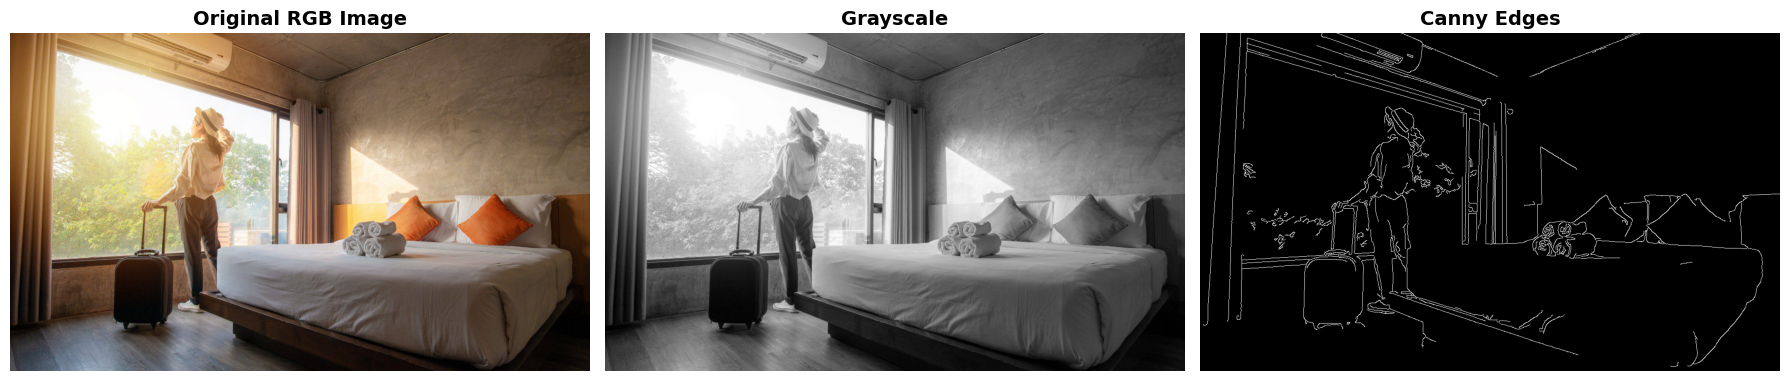

In [24]:
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb_img)
axes[0].set_title('Original RGB Image', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(gray_img, cmap='gray')
axes[1].set_title('Grayscale', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(canny_binary, cmap='gray')
axes[2].set_title('Canny Edges', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

---
# Step 2: Invert the Edge Map

Invert edges so regions are white and edges are black (required for distance transform).

In [25]:
print("Step 2: Invert the Edge Map")
print("=" * 60)

# Invert
inverted_edges = cv2.bitwise_not(canny_binary)

# Optional: close gaps
if CLOSE_GAPS:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KERNEL_SIZE, KERNEL_SIZE))
    closed_edges = cv2.morphologyEx(inverted_edges, cv2.MORPH_CLOSE, kernel, iterations=1)
    print(f"✓ Applied morphological closing ({KERNEL_SIZE}x{KERNEL_SIZE} kernel)")
else:
    closed_edges = inverted_edges
    print("  Skipped morphological closing")

print(f"Region pixels (white): {np.count_nonzero(closed_edges):,}")
print("✓ Edge map inverted!")

Step 2: Invert the Edge Map
  Skipped morphological closing
Region pixels (white): 819,878
✓ Edge map inverted!


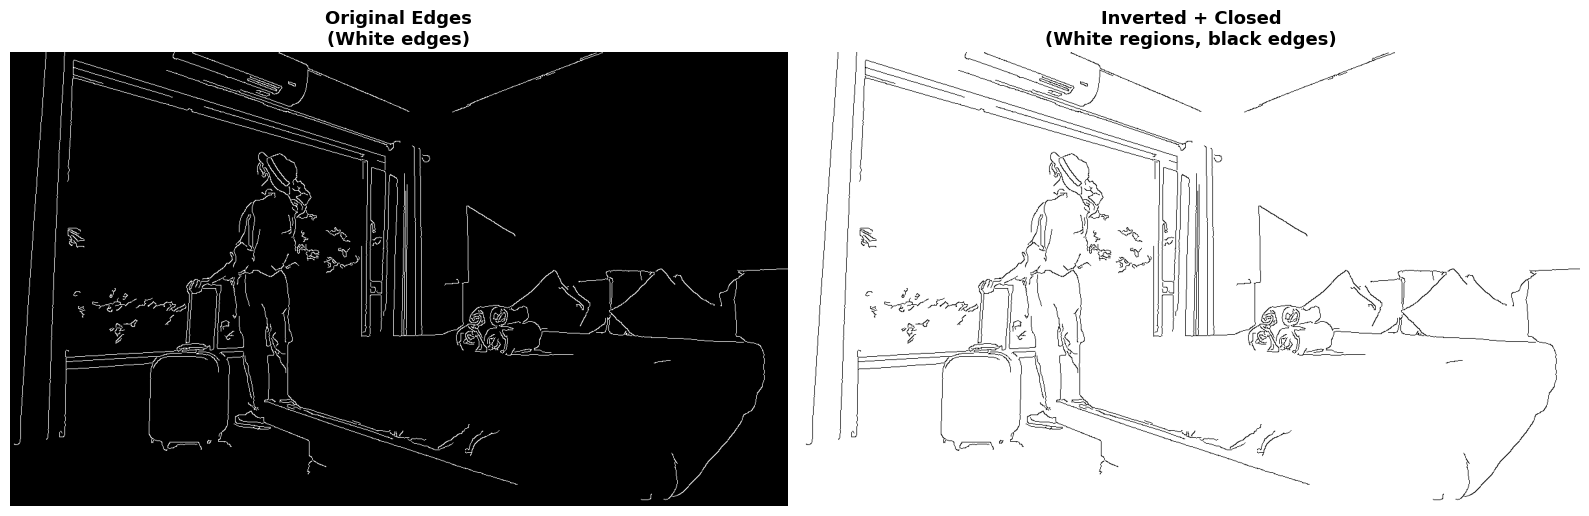

In [26]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(canny_binary, cmap='gray')
axes[0].set_title('Original Edges\n(White edges)', fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(closed_edges, cmap='gray')
axes[1].set_title('Inverted + Closed\n(White regions, black edges)', fontsize=13, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

---
# Step 3: Compute Distance Transform

Create the topographic landscape - distance from each pixel to nearest edge.

In [27]:
print("Step 3: Compute Distance Transform")
print("=" * 60)

# Compute distance transform
dist_transform = cv2.distanceTransform(closed_edges, cv2.DIST_L2, 5)

print(f"Distance range: {dist_transform.min():.2f} to {dist_transform.max():.2f}")
print(f"Mean distance: {dist_transform.mean():.2f}")

# Normalize for visualization
dist_normalized = cv2.normalize(dist_transform, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

print("✓ Distance transform computed!")

Step 3: Compute Distance Transform
Distance range: 0.00 to 293.68
Mean distance: 40.25
✓ Distance transform computed!


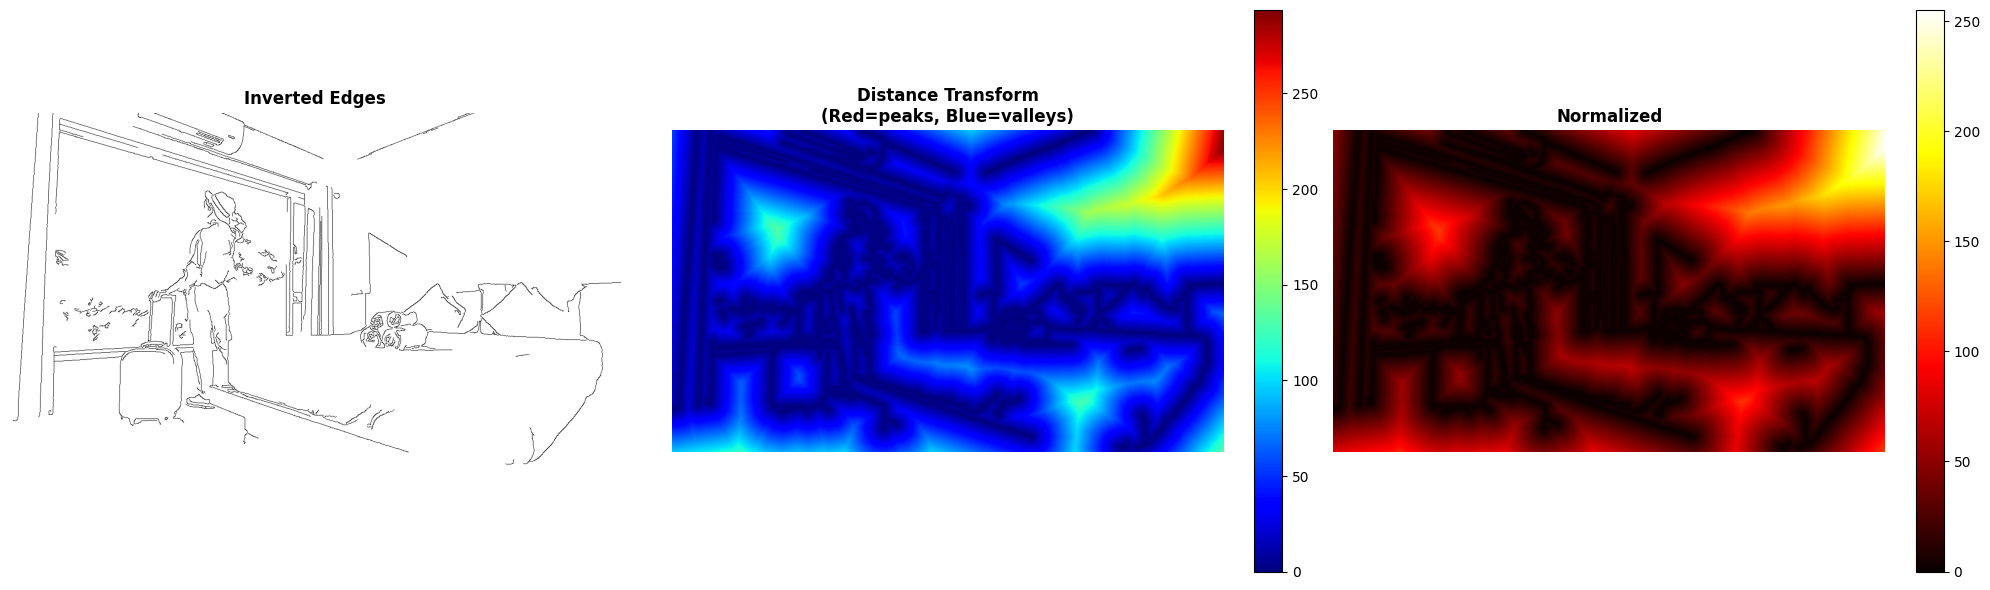

In [28]:
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(closed_edges, cmap='gray')
axes[0].set_title('Inverted Edges', fontsize=12, fontweight='bold')
axes[0].axis('off')

im1 = axes[1].imshow(dist_transform, cmap='jet')
axes[1].set_title('Distance Transform\n(Red=peaks, Blue=valleys)', fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(dist_normalized, cmap='hot')
axes[2].set_title('Normalized', fontsize=12, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

---
# Step 4: Find Markers (Local Maxima)

Threshold the distance transform to find peaks (region centers).

In [45]:
print("Step 4: Find Markers")
print("=" * 60)

# Threshold to find peaks
max_distance = dist_transform.max()
threshold_value = THRESHOLD_RATIO * max_distance

print(f"Max distance: {max_distance:.2f}")
print(f"Threshold ratio: {THRESHOLD_RATIO}")
print(f"Threshold value: {threshold_value:.2f}")

# Create binary mask of peaks
_, peak_mask = cv2.threshold(dist_transform, threshold_value, 255, cv2.THRESH_BINARY)
peak_mask = np.uint8(peak_mask)

# Label peaks
num_labels, markers = cv2.connectedComponents(peak_mask, connectivity=8)
num_markers = num_labels - 1

print(f"\n✓ Found {num_markers} markers")
print(f"  Labels: 1 to {num_markers}")
if num_markers < 2:
    print("  ⚠️  Warning: Too few markers! Try decreasing THRESHOLD_RATIO")
elif num_markers > 20:
    print("  ⚠️  Warning: Too many markers! Try increasing THRESHOLD_RATIO")

Step 4: Find Markers
Max distance: 293.68
Threshold ratio: 0.2
Threshold value: 58.74

✓ Found 10 markers
  Labels: 1 to 10


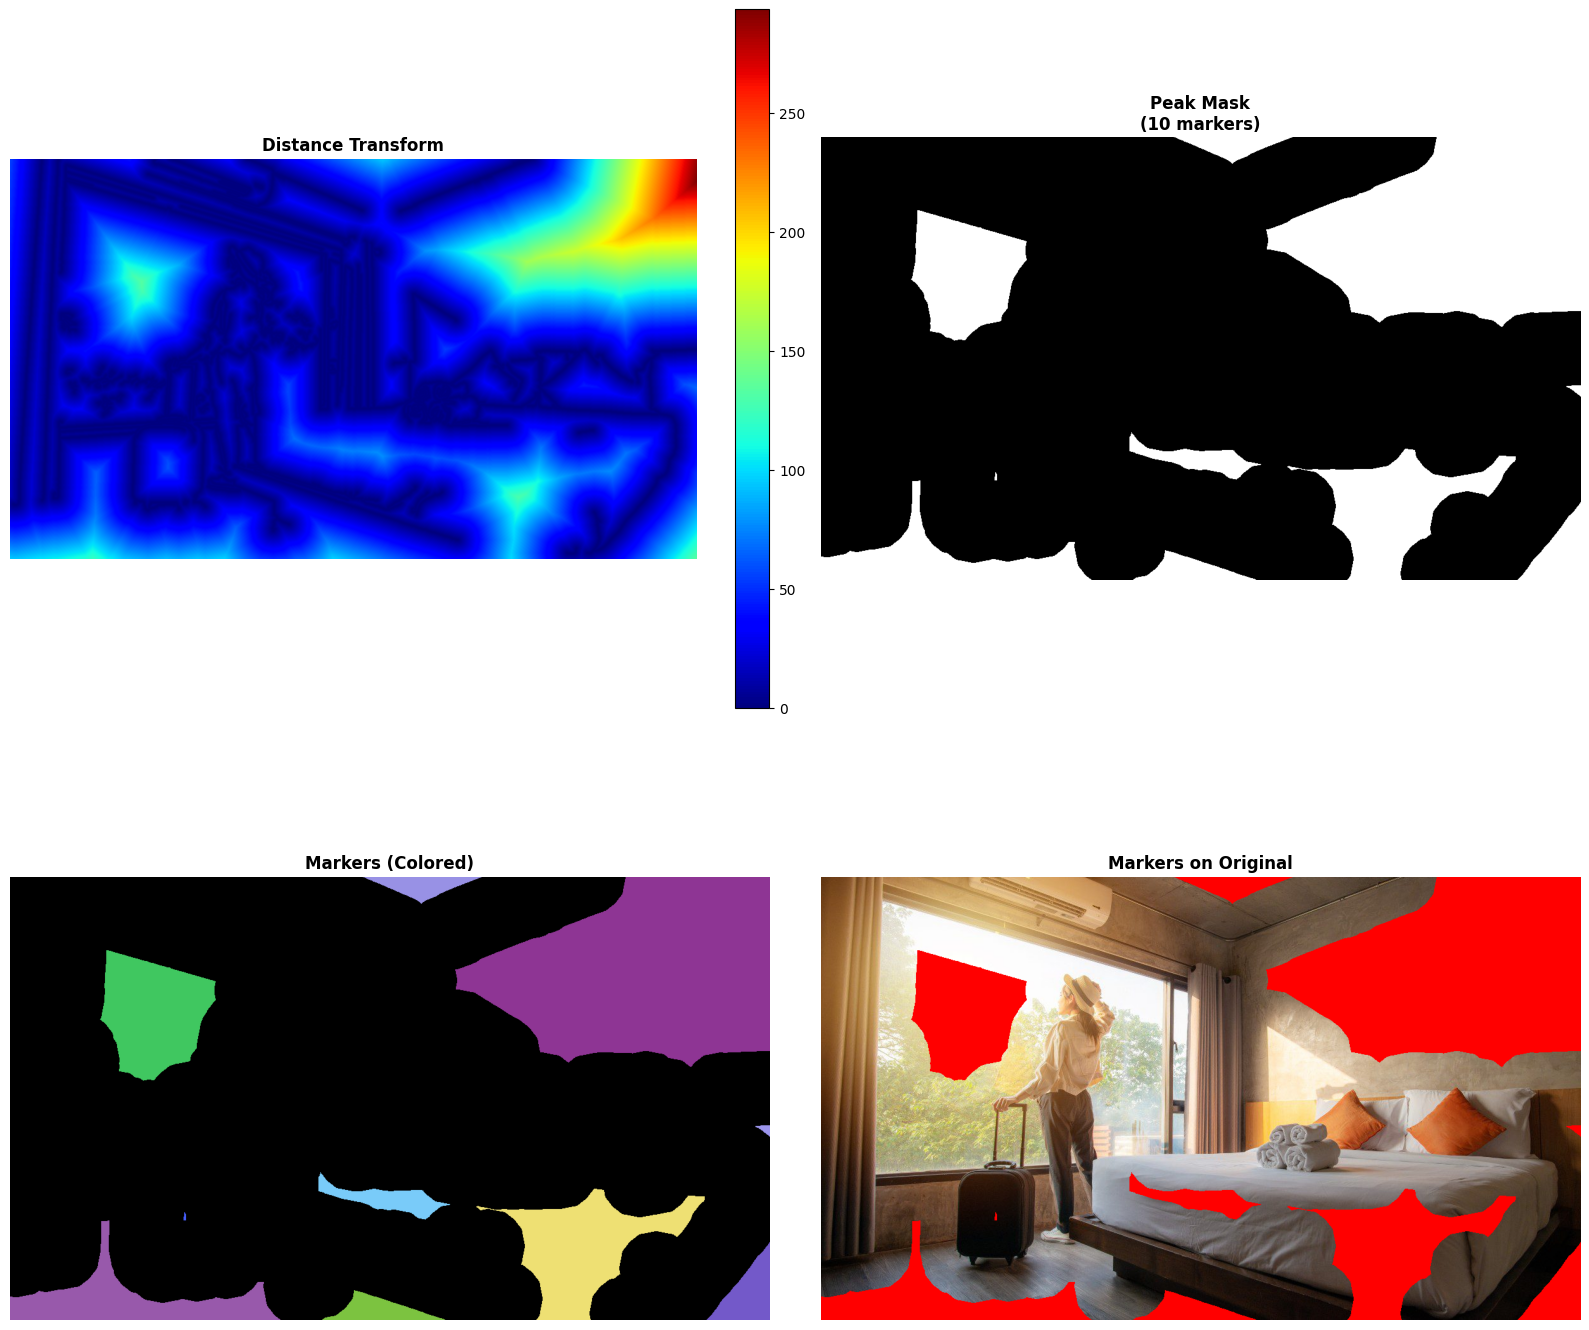

In [46]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

im = axes[0, 0].imshow(dist_transform, cmap='jet')
axes[0, 0].set_title('Distance Transform', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')
plt.colorbar(im, ax=axes[0, 0], fraction=0.046)

axes[0, 1].imshow(peak_mask, cmap='gray')
axes[0, 1].set_title(f'Peak Mask\n({num_markers} markers)', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# Colored markers
markers_colored = np.zeros((*markers.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, num_labels):
    color = np.random.randint(50, 255, 3, dtype=np.uint8)
    markers_colored[markers == label] = color

axes[1, 0].imshow(markers_colored)
axes[1, 0].set_title('Markers (Colored)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

overlay = rgb_img.copy()
overlay[peak_mask > 0] = [255, 0, 0]
axes[1, 1].imshow(overlay)
axes[1, 1].set_title('Markers on Original', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

---
# Step 5: Add Background Marker

Add border pixels as background (label=1) to keep regions separate.

In [47]:
print("Step 5: Add Background Marker")
print("=" * 60)

# Copy markers
markers_with_bg = markers.copy()

# Increment existing markers
markers_with_bg[markers_with_bg > 0] += 1

# Set border as background (label=1)
markers_with_bg[0:BORDER_THICKNESS, :] = 1
markers_with_bg[height-BORDER_THICKNESS:height, :] = 1
markers_with_bg[:, 0:BORDER_THICKNESS] = 1
markers_with_bg[:, width-BORDER_THICKNESS:width] = 1

# Convert to int32
markers_with_bg = markers_with_bg.astype(np.int32)

print(f"Background label: 1")
print(f"Region markers: 2 to {markers_with_bg.max()}")
print(f"Data type: {markers_with_bg.dtype}")
print("✓ Background marker added!")

Step 5: Add Background Marker
Background label: 1
Region markers: 2 to 11
Data type: int32
✓ Background marker added!


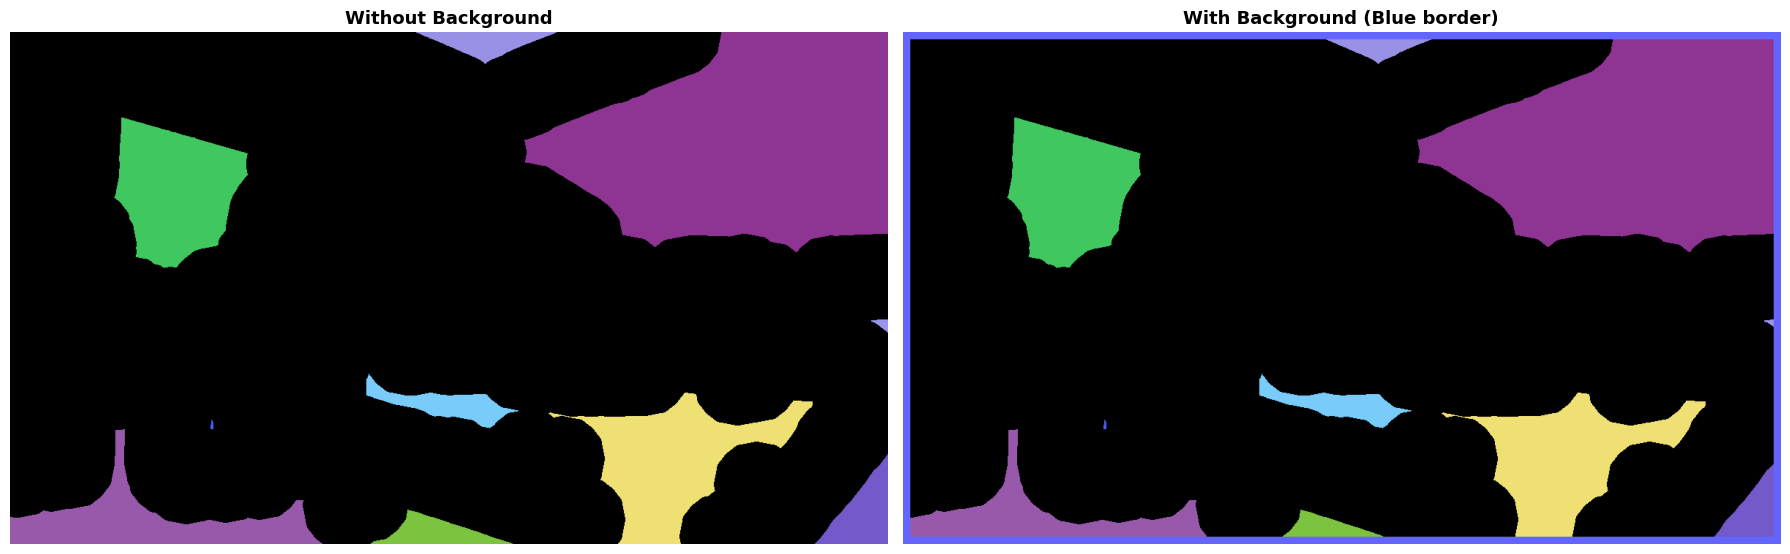

In [48]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Before
markers_vis_before = np.zeros((*markers.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_vis_before[markers == label] = color

axes[0].imshow(markers_vis_before)
axes[0].set_title('Without Background', fontsize=13, fontweight='bold')
axes[0].axis('off')

# After
markers_vis_after = np.zeros((*markers_with_bg.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers_with_bg):
    if label == 1:
        markers_vis_after[markers_with_bg == 1] = [100, 100, 255]  # Blue border
    elif label > 1:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_vis_after[markers_with_bg == label] = color

axes[1].imshow(markers_vis_after)
axes[1].set_title('With Background (Blue border)', fontsize=13, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

---
# Step 6: Apply Watershed Algorithm

The magic happens here - watershed floods from markers to create boundaries.

In [49]:
print("Step 6: Apply Watershed")
print("=" * 60)

# Save copy for visualization
markers_before = markers_with_bg.copy()

# Apply watershed (modifies in-place)
cv2.watershed(rgb_img, markers_with_bg)

# Count results
num_boundaries = np.sum(markers_with_bg == -1)
num_background = np.sum(markers_with_bg == 1)
region_labels = np.unique(markers_with_bg[markers_with_bg > 1])
num_regions = len(region_labels)

print(f"Boundary pixels: {num_boundaries:,}")
print(f"Background pixels: {num_background:,}")
print(f"Number of regions: {num_regions}")
print("✓ Watershed complete!")

Step 6: Apply Watershed
Boundary pixels: 13,007
Background pixels: 184,122
Number of regions: 10
✓ Watershed complete!


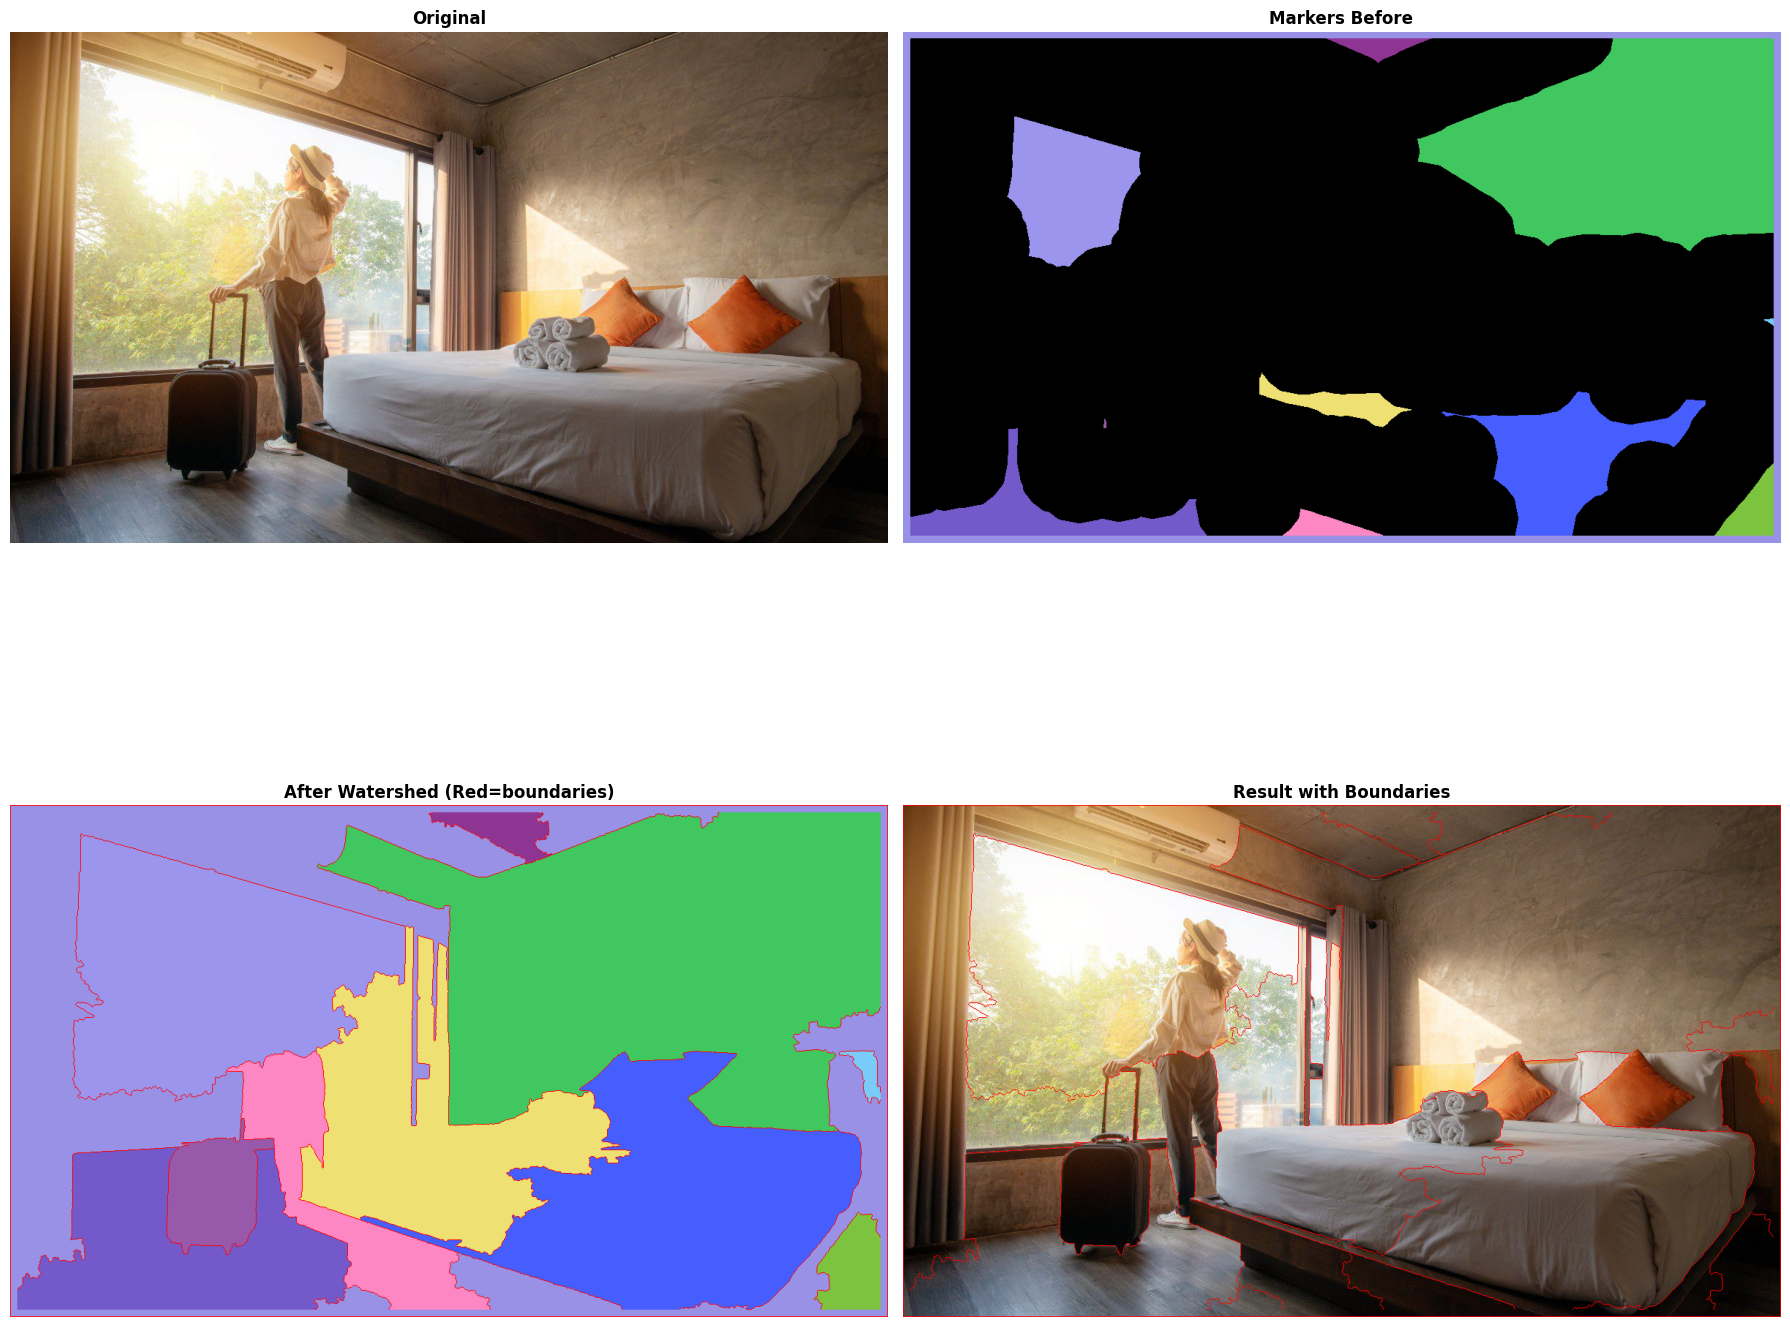

In [50]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 18))

axes[0, 0].imshow(rgb_img)
axes[0, 0].set_title('Original', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# Before watershed
markers_before_vis = np.zeros((*markers_before.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers_before):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_before_vis[markers_before == label] = color

axes[0, 1].imshow(markers_before_vis)
axes[0, 1].set_title('Markers Before', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# After watershed
markers_after_vis = np.zeros((*markers_with_bg.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers_with_bg):
    if label == -1:
        markers_after_vis[markers_with_bg == -1] = [255, 0, 0]
    elif label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_after_vis[markers_with_bg == label] = color

axes[1, 0].imshow(markers_after_vis)
axes[1, 0].set_title('After Watershed (Red=boundaries)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

# Result with boundaries
result_with_boundaries = rgb_img.copy()
result_with_boundaries[markers_with_bg == -1] = [255, 0, 0]

axes[1, 1].imshow(result_with_boundaries)
axes[1, 1].set_title('Result with Boundaries', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

---
# Step 7: Extract and Filter Regions

Remove boundaries and background, filter by area, renumber consecutively.

In [51]:
print("Step 7: Extract and Filter Regions")
print("=" * 60)

# Extract regions
regions_only = markers_with_bg.copy()
regions_only[regions_only == -1] = 0
regions_only[regions_only == 1] = 0

# Calculate areas
unique_labels, label_counts = np.unique(regions_only[regions_only > 0], return_counts=True)

print(f"Before filtering: {len(unique_labels)} regions")
print(f"Area range: {label_counts.min():,} to {label_counts.max():,} pixels")

# Filter by area
filtered_labels = []
region_areas_dict = {}

for label, count in zip(unique_labels, label_counts):
    region_areas_dict[label] = count
    if count >= MIN_REGION_AREA:
        filtered_labels.append(label)

print(f"\nAfter filtering (>= {MIN_REGION_AREA} pixels):")
print(f"  Kept: {len(filtered_labels)} regions")
print(f"  Removed: {len(unique_labels) - len(filtered_labels)} regions")

# Renumber consecutively
final_segmentation = np.zeros_like(regions_only)
for new_label, old_label in enumerate(filtered_labels, start=1):
    final_segmentation[regions_only == old_label] = new_label

print(f"\n✓ Final labels: 1 to {len(filtered_labels)}")

for new_label, old_label in enumerate(filtered_labels, start=1):
    area = region_areas_dict[old_label]
    pct = (area / total_pixels) * 100
    print(f"  Region {new_label}: {area:,} pixels ({pct:.2f}%)")

Step 7: Extract and Filter Regions
Before filtering: 10 regions
Area range: 1,610 to 215,927 pixels

After filtering (>= 1000 pixels):
  Kept: 10 regions
  Removed: 0 regions

✓ Final labels: 1 to 10
  Region 1: 5,869 pixels (0.70%)
  Region 2: 215,927 pixels (25.71%)
  Region 3: 107,806 pixels (12.83%)
  Region 4: 1,610 pixels (0.19%)
  Region 5: 84,089 pixels (10.01%)
  Region 6: 109,313 pixels (13.01%)
  Region 7: 17,148 pixels (2.04%)
  Region 8: 59,381 pixels (7.07%)
  Region 9: 8,675 pixels (1.03%)
  Region 10: 33,053 pixels (3.93%)


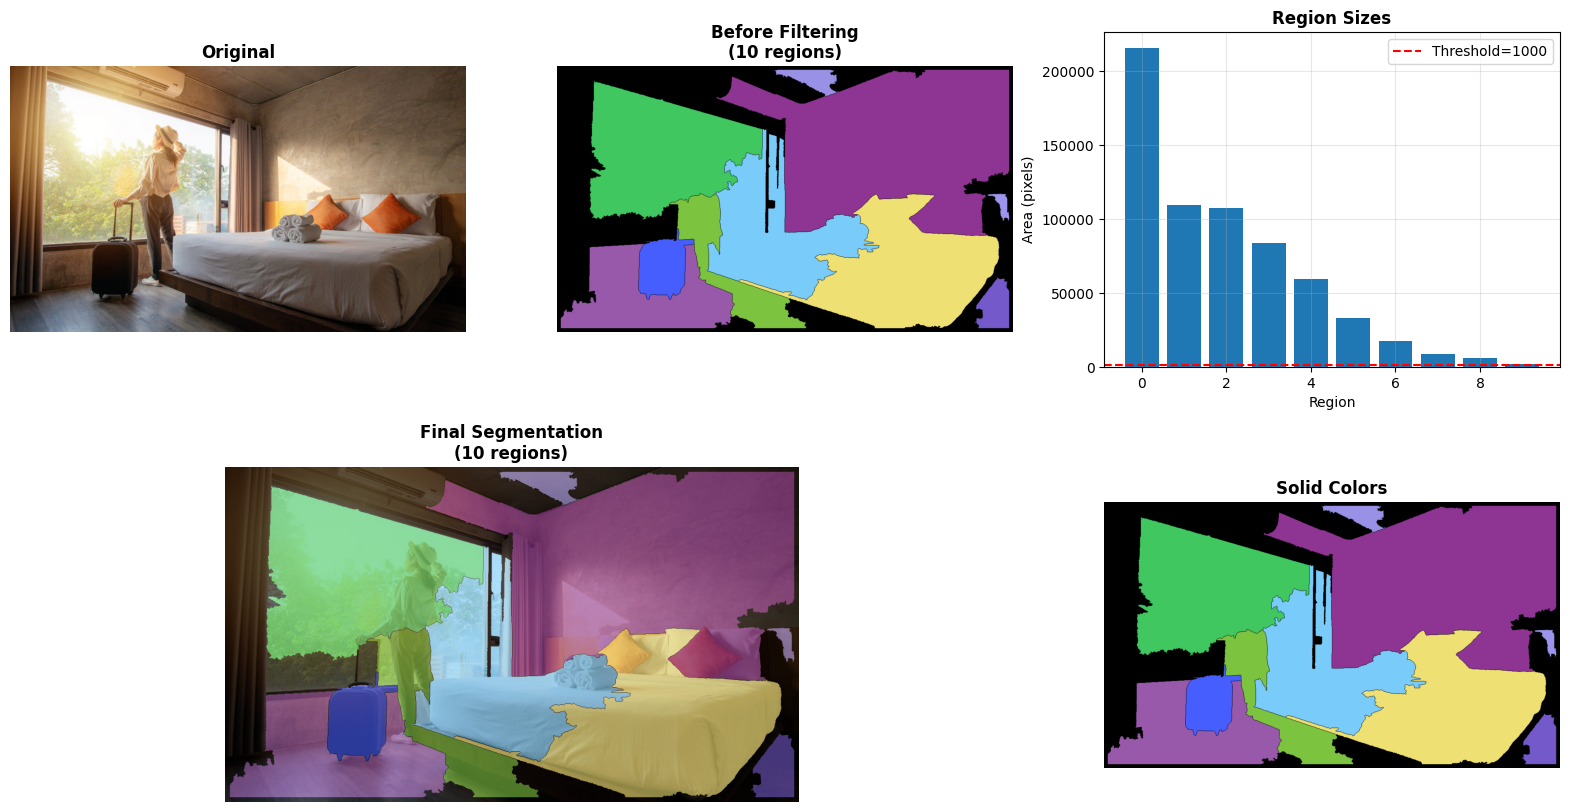

In [52]:
# Visualization
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.2)

ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(rgb_img)
ax1.set_title('Original', fontsize=12, fontweight='bold')
ax1.axis('off')

# Before filtering
ax2 = fig.add_subplot(gs[0, 1])
regions_before_vis = np.zeros((*regions_only.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(regions_only):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        regions_before_vis[regions_only == label] = color
ax2.imshow(regions_before_vis)
ax2.set_title(f'Before Filtering\n({len(unique_labels)} regions)', fontsize=12, fontweight='bold')
ax2.axis('off')

# Histogram
ax3 = fig.add_subplot(gs[0, 2])
ax3.bar(range(len(label_counts)), sorted(label_counts, reverse=True))
ax3.axhline(y=MIN_REGION_AREA, color='r', linestyle='--', label=f'Threshold={MIN_REGION_AREA}')
ax3.set_xlabel('Region', fontsize=10)
ax3.set_ylabel('Area (pixels)', fontsize=10)
ax3.set_title('Region Sizes', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# After filtering - colored
ax4 = fig.add_subplot(gs[1, :2])
final_vis = np.zeros((*final_segmentation.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, final_segmentation.max() + 1):
    color = np.random.randint(50, 255, 3, dtype=np.uint8)
    final_vis[final_segmentation == label] = color

overlay = (rgb_img * 0.4 + final_vis * 0.6).astype(np.uint8)
ax4.imshow(overlay)
ax4.set_title(f'Final Segmentation\n({len(filtered_labels)} regions)', fontsize=12, fontweight='bold')
ax4.axis('off')

# Solid colors
ax5 = fig.add_subplot(gs[1, 2])
ax5.imshow(final_vis)
ax5.set_title('Solid Colors', fontsize=12, fontweight='bold')
ax5.axis('off')

plt.show()

---
# Step 8: Extract Individual Shapes and Properties

Create masks and extract properties for each region.

In [53]:
print("Step 8: Extract Individual Shapes")
print("=" * 60)

regions_data = []

for label in range(1, final_segmentation.max() + 1):
    # Binary mask
    region_mask = (final_segmentation == label).astype(np.uint8) * 255
    
    # Area
    area = np.count_nonzero(region_mask)
    
    # Contour
    contours, _ = cv2.findContours(region_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    main_contour = contours[0] if contours else None
    
    # Bounding box
    if main_contour is not None:
        x, y, w, h = cv2.boundingRect(main_contour)
    else:
        y_coords, x_coords = np.where(region_mask > 0)
        x, y = x_coords.min(), y_coords.min()
        w, h = x_coords.max() - x + 1, y_coords.max() - y + 1
    
    # Centroid
    M = cv2.moments(region_mask)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        cx, cy = x + w//2, y + h//2
    
    region_info = {
        'label': label,
        'mask': region_mask,
        'contour': main_contour,
        'area': area,
        'bounding_box': (x, y, w, h),
        'centroid': (cx, cy),
        'percentage': (area / total_pixels) * 100
    }
    regions_data.append(region_info)
    
    print(f"Region {label}: {area:,} px ({region_info['percentage']:.2f}%), bbox=({x},{y},{w},{h}), center=({cx},{cy})")

print(f"\n✓ Extracted {len(regions_data)} regions!")

Step 8: Extract Individual Shapes
Region 1: 5,869 px (0.70%), bbox=(573,10,168,70), center=(673,33)
Region 2: 215,927 px (25.71%), bbox=(420,10,770,436), center=(881,208)
Region 3: 107,806 px (12.83%), bbox=(86,40,454,365), center=(270,227)
Region 4: 1,610 px (0.19%), bbox=(1134,336,56,72), center=(1171,364)
Region 5: 84,089 px (10.01%), bbox=(395,166,453,449), center=(575,436)
Region 6: 109,313 px (13.01%), bbox=(479,337,685,353), center=(913,538)
Region 7: 17,148 px (2.04%), bbox=(215,429,146,185), center=(278,528)
Region 8: 59,381 px (7.07%), bbox=(10,468,456,222), center=(231,605)
Region 9: 8,675 px (1.03%), bbox=(1099,557,91,133), center=(1152,633)
Region 10: 33,053 px (3.93%), bbox=(297,336,359,354), center=(453,527)

✓ Extracted 10 regions!


IndexError: index 3 is out of bounds for axis 1 with size 3

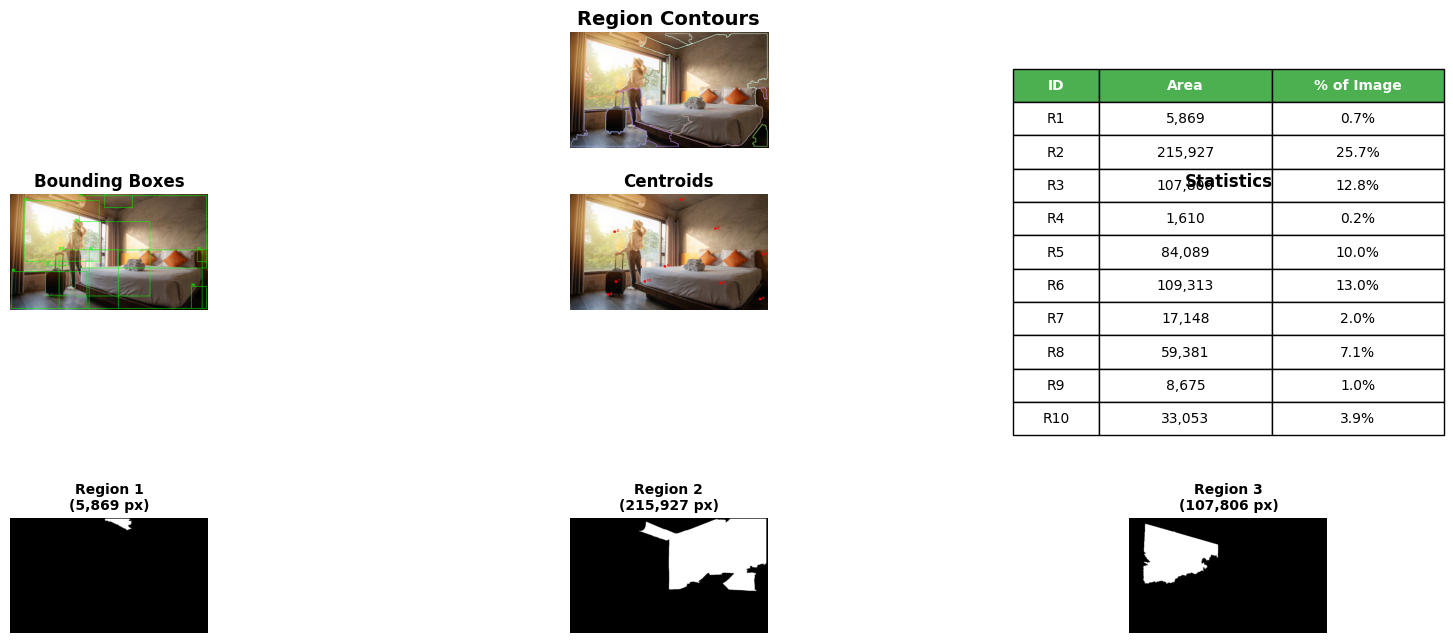

In [54]:
# Visualization
n_regions = len(regions_data)
n_cols = min(4, n_regions)
n_rows = (n_regions + n_cols - 1) // n_cols

fig = plt.figure(figsize=(20, max(12, n_rows * 3)))
gs = fig.add_gridspec(3 + n_rows, 3, hspace=0.4, wspace=0.3)

# Contours
ax1 = fig.add_subplot(gs[0, :])
result_contours = rgb_img.copy()
for region in regions_data:
    color = tuple(np.random.randint(100, 255, 3).tolist())
    if region['contour'] is not None:
        cv2.drawContours(result_contours, [region['contour']], -1, color, 2)
ax1.imshow(result_contours)
ax1.set_title('Region Contours', fontsize=14, fontweight='bold')
ax1.axis('off')

# Bboxes
ax2 = fig.add_subplot(gs[1, 0])
result_bbox = rgb_img.copy()
for region in regions_data:
    x, y, w, h = region['bounding_box']
    cv2.rectangle(result_bbox, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(result_bbox, f"R{region['label']}", (x, y-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
ax2.imshow(result_bbox)
ax2.set_title('Bounding Boxes', fontsize=12, fontweight='bold')
ax2.axis('off')

# Centroids
ax3 = fig.add_subplot(gs[1, 1])
result_centroids = rgb_img.copy()
for region in regions_data:
    cx, cy = region['centroid']
    cv2.circle(result_centroids, (cx, cy), 8, (255, 0, 0), -1)
    cv2.putText(result_centroids, f"{region['label']}", (cx+12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
ax3.imshow(result_centroids)
ax3.set_title('Centroids', fontsize=12, fontweight='bold')
ax3.axis('off')

# Stats table
ax4 = fig.add_subplot(gs[1, 2])
ax4.axis('off')
table_data = [['ID', 'Area', '% of Image']]
for region in regions_data:
    table_data.append([f"R{region['label']}", f"{region['area']:,}", f"{region['percentage']:.1f}%"])
table = ax4.table(cellText=table_data, cellLoc='center', loc='center', colWidths=[0.2, 0.4, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
for i in range(3):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')
ax4.set_title('Statistics', fontsize=12, fontweight='bold')

# Individual masks
for idx, region in enumerate(regions_data):
    row = 3 + idx // n_cols
    col = idx % n_cols
    ax = fig.add_subplot(gs[row, col])
    ax.imshow(region['mask'], cmap='gray')
    ax.set_title(f"Region {region['label']}\n({region['area']:,} px)", fontsize=10, fontweight='bold')
    ax.axis('off')

plt.show()

---
# Step 9: Save and Store Region Data

Save all results to disk in multiple formats.

In [19]:
# print("Step 9: Save Region Data")
# print("=" * 60)

# # Create output directory
# watershed_dir = os.path.join(OUTPUT_DIR, f"{TEST_IMAGE_NAME}_watershed")
# os.makedirs(watershed_dir, exist_ok=True)
# print(f"Output: {watershed_dir}\n")

# # 1. JSON
# regions_json = []
# for region in regions_data:
#     regions_json.append({
#         'label': int(region['label']),
#         'area': int(region['area']),
#         'percentage': float(region['percentage']),
#         'bounding_box': {'x': int(region['bounding_box'][0]), 'y': int(region['bounding_box'][1]),
#                         'width': int(region['bounding_box'][2]), 'height': int(region['bounding_box'][3])},
#         'centroid': {'x': int(region['centroid'][0]), 'y': int(region['centroid'][1])},
#         'contour_points': region['contour'].tolist() if region['contour'] is not None else []
#     })

# json_path = os.path.join(watershed_dir, 'regions_data.json')
# with open(json_path, 'w') as f:
#     json.dump(regions_json, f, indent=2)
# print(f"✓ Saved JSON: {json_path}")

# # 2. Pickle
# pickle_path = os.path.join(watershed_dir, 'regions_data.pkl')
# with open(pickle_path, 'wb') as f:
#     pickle.dump(regions_data, f)
# print(f"✓ Saved Pickle: {pickle_path}")

# # 3. Individual masks
# masks_dir = os.path.join(watershed_dir, 'masks')
# os.makedirs(masks_dir, exist_ok=True)
# for region in regions_data:
#     mask_path = os.path.join(masks_dir, f"region_{region['label']:02d}_mask.png")
#     cv2.imwrite(mask_path, region['mask'])
# print(f"✓ Saved {len(regions_data)} masks to: {masks_dir}")

# # 4. Segmentation array
# seg_npy_path = os.path.join(watershed_dir, 'segmentation_labels.npy')
# np.save(seg_npy_path, final_segmentation)
# print(f"✓ Saved NPY: {seg_npy_path}")

# # 5. Colored visualization
# segmentation_colored = np.zeros((*final_segmentation.shape, 3), dtype=np.uint8)
# np.random.seed(42)
# for label in range(1, final_segmentation.max() + 1):
#     color = np.random.randint(50, 255, 3, dtype=np.uint8)
#     segmentation_colored[final_segmentation == label] = color

# colored_path = os.path.join(watershed_dir, 'segmentation_colored.png')
# cv2.imwrite(colored_path, cv2.cvtColor(segmentation_colored, cv2.COLOR_RGB2BGR))
# print(f"✓ Saved colored PNG: {colored_path}")

# # 6. Summary text
# summary_path = os.path.join(watershed_dir, 'summary.txt')
# with open(summary_path, 'w') as f:
#     f.write(f"Watershed Segmentation Summary\n")
#     f.write(f"="*60 + "\n")
#     f.write(f"Image: {TEST_IMAGE_NAME}\n")
#     f.write(f"Size: {width} x {height} pixels\n")
#     f.write(f"Total regions: {len(regions_data)}\n")
#     f.write(f"Min area threshold: {MIN_REGION_AREA} pixels\n\n")
#     f.write(f"Region Details:\n")
#     f.write(f"-"*60 + "\n")
#     for region in regions_data:
#         f.write(f"Region {region['label']}:\n")
#         f.write(f"  Area: {region['area']:,} pixels ({region['percentage']:.2f}%)\n")
#         f.write(f"  BBox: {region['bounding_box']}\n")
#         f.write(f"  Centroid: {region['centroid']}\n\n")

# print(f"✓ Saved summary: {summary_path}")
# print(f"\n✓ All data saved to: {watershed_dir}")

In [20]:
# # Final Summary Visualization
# fig, axes = plt.subplots(2, 2, figsize=(18, 16))

# axes[0, 0].imshow(rgb_img)
# axes[0, 0].set_title('Input: Original RGB', fontsize=13, fontweight='bold')
# axes[0, 0].axis('off')

# axes[0, 1].imshow(canny_binary, cmap='gray')
# axes[0, 1].set_title('Input: Canny Edges', fontsize=13, fontweight='bold')
# axes[0, 1].axis('off')

# im = axes[1, 0].imshow(dist_transform, cmap='jet')
# axes[1, 0].set_title('Intermediate: Distance Transform', fontsize=13, fontweight='bold')
# axes[1, 0].axis('off')
# plt.colorbar(im, ax=axes[1, 0], fraction=0.046)

# axes[1, 1].imshow(segmentation_colored)
# axes[1, 1].set_title(f'Output: Final Segmentation\n({len(regions_data)} regions)', fontsize=13, fontweight='bold')
# axes[1, 1].axis('off')

# plt.suptitle('Watershed Segmentation Pipeline', fontsize=16, fontweight='bold', y=0.98)
# plt.tight_layout()
# plt.show()

# print("\n" + "="*60)
# print("WATERSHED SEGMENTATION COMPLETE!")
# print("="*60)
# print(f"Image: {TEST_IMAGE_NAME}")
# print(f"Size: {width} x {height} pixels")
# print(f"Total regions: {len(regions_data)}")
# print(f"\nRegion Summary:")
# for region in regions_data:
#     print(f"  Region {region['label']}: {region['area']:,} pixels ({region['percentage']:.1f}%)")
# print(f"\n✓ All results saved to: {watershed_dir}")
# print(f"✓ Pipeline completed successfully!")